<a href="https://colab.research.google.com/github/David-NNdungu/econ5200-cheng-hoekstra-replication/blob/main/Castle_Doctrine_Replication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Castle Doctrine and Homicide: Replication and Robustness Checks

I replicate Cheng and Hoekstra (2013), Table 5, Panel A, columns 1–3, and carry out five robustness checks.

## Running this notebook

In Google Colab, select **Runtime → Run all**. This notebook includes the analysis code and downloads the public dataset in its first cell. No repository upload, Drive mount or API key is needed. An internet connection is required to download the data and install any missing packages. All analysis outputs are regenerated during the run.

The dataset is the public `castle.dta` file from Scott Cunningham’s Mixtape repository. I verify its SHA-256 checksum before using it. The accompanying project report discusses the identification assumptions and related studies.


In [1]:
from pathlib import Path
import sys
import subprocess
import importlib.util
import hashlib
import json

packages = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
            "statsmodels": "statsmodels", "matplotlib": "matplotlib", "IPython": "ipython"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

ROOT = Path.cwd() / "castle_doctrine_run"
(ROOT / "data").mkdir(parents=True, exist_ok=True)
from urllib.request import urlopen
DATA_URL = "https://raw.githubusercontent.com/scunning1975/mixtape/9471dd0c45477386bf208516882895af340f3d33/castle.dta"
with urlopen(DATA_URL, timeout=60) as response:
    data_bytes = response.read()
assert hashlib.sha256(data_bytes).hexdigest() == '804633c161827b6c0824f86f239046386d1a8266a866f83bf5ddb2aa762a5f29', "Dataset checksum failed"
(ROOT / "data/castle.dta").write_bytes(data_bytes)
print("Dataset ready. The next cells define and run the analysis.")

Dataset ready. The next cells define and run the analysis.


## Analysis functions

I define the estimation and robustness procedures here so that the notebook can run independently.

In [2]:
"""Castle-doctrine replication and prespecified sensitivity exercises."""
from pathlib import Path
import hashlib
import itertools
import json
import time

import numpy as np
import pandas as pd
import scipy.linalg as la
from scipy.stats import t as student_t, chi2
import statsmodels.api as sm
from statsmodels.stats.sandwich_covariance import cov_cluster
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

CONTROLS = ['l_police', 'l_income', 'unemployrt', 'poverty', 'l_prisoner',
            'l_lagprisoner', 'l_exp_subsidy', 'l_exp_pubwelfare',
            'blackm_15_24', 'whitem_15_24', 'blackm_25_44', 'whitem_25_44']
PAPER = {'SY': (0.0801, 0.0342), 'RY': (0.0946, 0.0279), 'RYX': (0.0937, 0.0290)}


def design(data, region=False, controls=False, treatment='cdl'):
    """Full-rank design: retain treatment, prune only redundant nuisance indicators."""
    d = data.reset_index(drop=True).copy()
    if 'region' not in d:
        d['region'] = d[['northeast', 'midwest', 'south', 'west']].idxmax(axis=1)
    nuisance = [pd.DataFrame({'const': np.ones(len(d))}),
                pd.get_dummies(d.sid.astype(str), prefix='state', drop_first=True, dtype=float)]
    time_key = d.region.astype(str) + '_' + d.year.astype(str) if region else d.year.astype(str)
    nuisance.append(pd.get_dummies(time_key, prefix='time', drop_first=True, dtype=float))
    if controls:
        nuisance.append(d[CONTROLS].astype(float))
    z = pd.concat(nuisance, axis=1)
    _, r, piv = la.qr(z.to_numpy(), mode='economic', pivoting=True)
    rank = np.linalg.matrix_rank(r)
    z = z.iloc[:, sorted(piv[:rank])]
    X = pd.concat([d[[treatment]].astype(float), z], axis=1)
    if np.linalg.matrix_rank(X.to_numpy()) != X.shape[1]:
        raise ValueError('Treatment is not identified after fixed effects.')
    return d, X


def fit_model(data, region=False, controls=False, weighted=True, outcome='l_homicide', treatment='cdl'):
    d, X = design(data, region, controls, treatment)
    w = d.popwt.to_numpy(dtype=float) if weighted else np.ones(len(d))
    # Normalising analytic weights has no effect on beta or the cluster sandwich.
    w /= w.mean()
    fit = sm.WLS(d[outcome].astype(float), X, weights=w).fit()
    n, rank = X.shape
    groups = d.sid.to_numpy()
    G = d.sid.nunique()
    # State FE are nested in the state clusters. Count the nonabsorbed rank,
    # including one intercept, for the small-sample correction used here.
    k_absorbed = rank - (G - 1)
    correction = G / (G - 1) * (n - 1) / (n - k_absorbed)
    covariance = cov_cluster(fit, groups, use_correction=False) * correction
    j = X.columns.get_loc(treatment)
    beta = float(fit.params.iloc[j])
    se = float(np.sqrt(covariance[j, j]))
    critical = student_t.ppf(.975, G - 1)
    default_se = float(np.sqrt(cov_cluster(fit, groups, use_correction=True)[j, j]))
    result = {'beta': beta, 'se': se, 'lo': beta-critical*se, 'hi': beta+critical*se,
              'p': float(2*student_t.sf(abs(beta/se), G-1)), 'exact_pct': float(100*np.expm1(beta)),
              'n': n, 'clusters': G, 'rank': rank, 'k_absorbed': k_absorbed,
              'default_cluster_se': default_se, 'correction': correction}
    return result, fit, d, X


def arrays(data, outcome='l_homicide', weighted=True):
    states = np.sort(data.sid.unique())
    years = np.sort(data.year.unique())
    panel = data.pivot(index='sid', columns='year', values=outcome).loc[states, years]
    if panel.isna().any().any():
        raise ValueError('Group-time calculations require a complete outcome panel.')
    by_state = data.groupby('sid').first().loc[states]
    return (panel.to_numpy(dtype=float), by_state.effyear.to_numpy(dtype=float),
            by_state.popwt.to_numpy(dtype=float) if weighted else np.ones(len(states)), years)


def group_time(Y, cohort, weights, years, control='never', counts=None, base_offset=-1, balanced=False):
    """Unconditional two-by-two cohort/year DIDs, not conditional/doubly-robust CS."""
    w = weights.copy() if counts is None else weights * counts
    cells = []
    for g in np.sort(np.unique(cohort[np.isfinite(cohort)])):
        treated = cohort == g
        if w[treated].sum() == 0:
            continue
        base = int(g + base_offset)
        if base not in years:
            continue
        b = int(np.flatnonzero(years == base)[0])
        for j, year in enumerate(years):
            e = int(year-g)
            if year == base or (balanced and not -4 <= e <= 1):
                continue
            comparison = np.isnan(cohort) if control == 'never' else (np.isnan(cohort) | (cohort > max(year, base)))
            comparison &= ~treated
            if w[comparison].sum() == 0:
                continue
            delta = Y[:,j] - Y[:,b]
            att = np.average(delta[treated], weights=w[treated]) - np.average(delta[comparison], weights=w[comparison])
            cells.append((int(g), int(year), e, float(att), float(w[treated].sum())))
    frame = pd.DataFrame(cells, columns=['cohort','year','event','att','weight'])
    post = frame[frame.event >= 0]
    overall = np.average(post.att, weights=post.weight)
    events = {int(e): float(np.average(f.att, weights=f.weight)) for e,f in frame.groupby('event')}
    return float(overall), events, frame


def group_bootstrap(Y, cohort, weights, years, reps=999, seed=20261119, **kwargs):
    """Resample whole state histories; retain estimated weights and composition per draw."""
    rng = np.random.default_rng(seed)
    estimates, events = [], []
    for _ in range(reps):
        counts = rng.multinomial(len(cohort), np.repeat(1/len(cohort), len(cohort)))
        estimate, by_e, _ = group_time(Y,cohort,weights,years,counts=counts,**kwargs)
        estimates.append(estimate)
        events.append(by_e)
    return np.asarray(estimates), pd.DataFrame(events)


def wild_bootstrap(data, region=True, reps=1999, seed=20261120):
    result, fit, d, Xframe = fit_model(data, region=region)
    X = fit.model.wexog
    y = fit.model.wendog
    j = Xframe.columns.get_loc('cdl')
    Z = np.delete(X,j,axis=1)
    fitted_null = Z @ np.linalg.lstsq(Z,y,rcond=None)[0]
    residual_null = y-fitted_null
    ids = pd.factorize(d.sid)[0]
    G = len(np.unique(ids))
    rng = np.random.default_rng(seed)
    weights = rng.choice([-1.,1.],size=(reps,G))
    ys = fitted_null[None,:] + residual_null[None,:]*weights[:,ids]
    bread = np.linalg.inv(X.T@X)
    betas = ys@X@bread
    residuals = ys-betas@X.T
    influence = X@bread[:,j]
    scores = np.column_stack([(residuals[:,ids==g]*influence[ids==g]).sum(axis=1) for g in range(G)])
    se_star = np.sqrt(result['correction']*(scores**2).sum(axis=1))
    t_star = betas[:,j]/se_star
    observed = result['beta']/result['se']
    exceed = int((np.abs(t_star) >= abs(observed)).sum())
    p = (exceed+1)/(reps+1)
    # Validate the vectorised sandwich against direct WLS computations.
    for b in [0, reps//2, reps-1]:
        direct = sm.OLS(ys[b],X).fit()
        v = cov_cluster(direct,ids,use_correction=False)*result['correction']
        assert np.isclose(t_star[b],direct.params[j]/np.sqrt(v[j,j]),rtol=1e-7,atol=1e-8)
    return {'beta':result['beta'],'cluster_se':result['se'],'cluster_t_p':result['p'],
            'wild_p':float(p),'wild_mc_se':float(np.sqrt(p*(1-p)/reps)),
            'draws':reps,'exceedances':exceed,'seed':seed}, pd.DataFrame({'t_star':t_star})


def run(root):
    start = time.perf_counter()
    out = Path(root)/'output'
    out.mkdir(exist_ok=True)
    data = pd.read_stata(Path(root)/'data/castle.dta', convert_categoricals=False)
    assert len(data)==550 and data.sid.nunique()==50 and not data.duplicated(['sid','year']).any()
    data['region'] = data[['northeast','midwest','south','west']].idxmax(axis=1)
    rows=[]
    for label,region,controls in [('SY',False,False),('RY',True,False),('RYX',True,True)]:
        r,*_ = fit_model(data,region,controls)
        paper_b,paper_se = PAPER[label]
        rows.append({'model':label,'paper_beta':paper_b,'replication_beta':r['beta'],
                     'coefficient_gap':r['beta']-paper_b,'relative_gap_pct':100*(r['beta']-paper_b)/paper_b,
                     'paper_se':paper_se,'replication_se':r['se'],'se_gap':r['se']-paper_se,**r})
    headline=pd.DataFrame(rows)
    headline.to_csv(out/'headline_table.csv',index=False)
    cohort=data.groupby('sid').effyear.first()
    cohort.value_counts(dropna=False).rename_axis('cohort').reset_index(name='states').to_csv(out/'adoption_counts.csv',index=False)
    characteristics={'n':len(data),'states':int(data.sid.nunique()),'first_year':int(data.year.min()),
      'last_year':int(data.year.max()),'adopters':int(cohort.notna().sum()),'never':int(cohort.isna().sum()),
      'partial_rows':int(((data.cdl>0)&(data.cdl<1)).sum()),'positive_homicide':bool((data.homicide>0).all()),
      'weight_max_relative_diff_from_mean_pop':float(np.max(np.abs(data.groupby('sid').popwt.first()-data.groupby('sid').population.mean())/data.groupby('sid').population.mean()))}
    (out/'data_checks.json').write_text(json.dumps(characteristics,indent=2))
    Y,g,w,years=arrays(data)
    group_rows=[]
    event_outputs={}
    for control in ['never','notyet']:
        att,events,cells=group_time(Y,g,w,years,control=control)
        boot,boot_events=group_bootstrap(Y,g,w,years,control=control)
        group_rows.append({'model':'Group-time '+control,'beta':att,'se':float(boot.std(ddof=1)),
                          'lo':float(np.quantile(boot,.025)),'hi':float(np.quantile(boot,.975)),
                          'exact_pct':float(100*np.expm1(att)),'bootstrap_draws':len(boot)})
        cells.to_csv(out/f'group_time_{control}.csv',index=False)
        pd.DataFrame({'draw':boot}).to_csv(out/f'bootstrap_{control}.csv',index=False)
        event_outputs[control]=(events,boot_events)
    # Binary TWFE isolates treatment-dose coding from the estimator change.
    data['any_exposure']=(data.year>=data.effyear).astype(float)
    r,*_=fit_model(data,treatment='any_exposure')
    group_rows.insert(0,{'model':'TWFE binary exposure',**r})
    r,*_=fit_model(data)
    group_rows.insert(0,{'model':'TWFE fractional exposure',**r})
    gt=pd.DataFrame(group_rows)
    gt.to_csv(out/'estimator_comparison.csv',index=False)
    # Cohort-balanced event window: all five cohorts observed at every plotted e.
    _,bal_events,bal_cells=group_time(Y,g,w,years,balanced=True)
    bal_boot,bal_be=group_bootstrap(Y,g,w,years,balanced=True)
    _,alternate,_=group_time(Y,g,w,years,balanced=True,base_offset=-2)
    es=[]
    for e in range(-4,2):
        if e==-1:
            es.append({'event':e,'beta':0.,'se':0.,'lo':0.,'hi':0.,'alternate_reference':alternate[e]})
            continue
        es.append({'event':e,'beta':bal_events[e],'se':bal_be[e].std(ddof=1),
                   'lo':bal_be[e].quantile(.025),'hi':bal_be[e].quantile(.975),
                   'alternate_reference':alternate.get(e,0.)})
    event=pd.DataFrame(es)
    event.to_csv(out/'balanced_event_study.csv',index=False)
    pre=np.array([bal_events[e] for e in [-4,-3,-2]])
    covariance=bal_be[[-4,-3,-2]].cov().to_numpy()
    pre_wald=float(pre@np.linalg.pinv(covariance)@pre)
    pretest={'wald':pre_wald,'df':3,'p':float(chi2.sf(pre_wald,3)),
             'balanced_e1':float(bal_events[1]),'e1_reference_minus2':float(alternate[1])}
    (out/'pretrend_test.json').write_text(json.dumps(pretest,indent=2))
    specs=[]
    samples={'All states':data,'No Florida':data[data.state!='Florida'],
             'No South':data[data.region!='south']}
    for sample,weighted,region,controls in itertools.product(samples,[True,False],[False,True],[False,True]):
        r,*_=fit_model(samples[sample],region,controls,weighted)
        specs.append({'sample':sample,'weighted':weighted,'region_year':region,'controls':controls,**r})
    curve=pd.DataFrame(specs)
    curve.to_csv(out/'specification_curve.csv',index=False)
    # Use RY for the influence exercise, avoiding nuisance-control misspecification.
    base=fit_model(data,region=True)[0]
    loo=[]
    for state in sorted(data.state.unique()):
        r,*_=fit_model(data[data.state!=state],region=True)
        loo.append({'omitted_state':state,'change':r['beta']-base['beta'],**r})
    loo=pd.DataFrame(loo).sort_values('beta')
    loo.to_csv(out/'leave_one_state_out.csv',index=False)
    inference,draws=wild_bootstrap(data)
    pd.DataFrame([inference]).to_csv(out/'inference.csv',index=False)
    draws.to_csv(out/'wild_bootstrap_draws.csv',index=False)
    # Original-style placebo crime, diagnostic only (not counted as a novel extension).
    placebo=[]
    for outcome in ['l_larceny','l_motor']:
        for region in [False,True]:
            r,*_=fit_model(data,region=region,outcome=outcome)
            placebo.append({'outcome':outcome,'region_year':region,**r})
    pd.DataFrame(placebo).to_csv(out/'placebo_outcomes.csv',index=False)

    plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
    fig,ax=plt.subplots(figsize=(8,3.8))
    ax.errorbar(event.event,event.beta,yerr=[event.beta-event.lo,event.hi-event.beta],fmt='o-',color='#174C68',capsize=3)
    ax.axhline(0,color='gray',lw=1);ax.axvline(-.5,color='gray',ls='--',lw=1)
    ax.set(xlabel='Years relative to adoption (−1 is the reference)',ylabel='Log homicide rate difference',title='Cohort-balanced group-time event study')
    fig.tight_layout();fig.savefig(out/'event_study.png',dpi=180);plt.close(fig)
    ordered=curve.sort_values('beta').reset_index(drop=True)
    fig,ax=plt.subplots(figsize=(8,3.8))
    colors=np.where(ordered['weighted'],'#174C68','#B97B30')
    for i,row in ordered.iterrows():
        ax.plot([i,i],[row.lo,row.hi],color=colors[i],alpha=.65)
    ax.scatter(ordered.index,ordered.beta,c=colors,s=24)
    ax.axhline(0,color='gray',lw=1);ax.axhline(base['beta'],color='#174C68',ls='--',label='Weighted region-year baseline')
    ax.set(xlabel='Prespecified specification, sorted by coefficient',ylabel='Coefficient on fractional exposure',title='24-model specification curve (95% state-cluster intervals)')
    ax.legend(fontsize=8);fig.tight_layout();fig.savefig(out/'specification_curve.png',dpi=180);plt.close(fig)
    fig,ax=plt.subplots(figsize=(8,3.8))
    ax.plot(np.arange(len(loo)),loo.beta,'o',color='#174C68',ms=4)
    ax.axhline(base['beta'],color='gray',ls='--',label='All states')
    for state in ['Florida','Texas','California']:
        idx=int(np.flatnonzero(loo.omitted_state.to_numpy()==state)[0]);ax.annotate(state,(idx,loo.iloc[idx].beta),xytext=(3,7),textcoords='offset points',fontsize=8)
    ax.set(xlabel='Omitted state, sorted by resulting coefficient',ylabel='Coefficient on fractional exposure',title='Leave-one-state-out sensitivity: region-year model')
    fig.tight_layout();fig.savefig(out/'state_influence.png',dpi=180);plt.close(fig)
    summary={'headline':headline.to_dict('records'),'group':gt.to_dict('records'),'pretrend':pretest,
             'curve_min':float(curve.beta.min()),'curve_max':float(curve.beta.max()),
             'curve_positive':int((curve.beta>0).sum()),'curve_significant':int((curve.p<.05).sum()),
             'loo_min':float(loo.beta.min()),'loo_max':float(loo.beta.max()),
             'no_florida':loo[loo.omitted_state=='Florida'].iloc[0].to_dict(),
             'inference':inference,'data':characteristics,'analysis_seconds':time.perf_counter()-start}
    (out/'summary.json').write_text(json.dumps(summary,indent=2))
    return summary


In [3]:
run(ROOT)
castle = pd.read_stata(ROOT / "data/castle.dta", convert_categoricals=False)
summary = json.loads((ROOT / "output/summary.json").read_text())
print(f"{len(castle)} state-year observations, {castle.sid.nunique()} states")

550 state-year observations, 50 states


## Data checks

I preserve fractional-year exposure, supplied average-population weights and all observations with positive homicide rates.

In [4]:
print(json.dumps(summary['data'], indent=2))
print(castle.groupby('sid').effyear.first().value_counts(dropna=False).sort_index())

{
  "n": 550,
  "states": 50,
  "first_year": 2000,
  "last_year": 2010,
  "adopters": 21,
  "never": 29,
  "partial_rows": 21,
  "positive_homicide": true,
  "weight_max_relative_diff_from_mean_pop": 5.206334432128064e-08
}
effyear
2005.0     1
2006.0    13
2007.0     4
2008.0     2
2009.0     1
NaN       29
Name: count, dtype: int64


## Direct replication

I fit state-and-year effects, state-and-region-year effects, and the region-year model with the supplied controls. Standard errors cluster by state with the documented absorbed-effects small-sample convention.

In [5]:
for name, region, controls in [('SY',False,False),('RY',True,False),('RYX',True,True)]:
    result, fitted, data_used, design_matrix = fit_model(castle, region=region, controls=controls)
    print(name, json.dumps(result, indent=2))

SY {
  "beta": 0.0800635103382449,
  "se": 0.03422468997421425,
  "lo": 0.011286420867638591,
  "hi": 0.1488405998088512,
  "p": 0.023437817596895068,
  "exact_pct": 8.335586978784251,
  "n": 550,
  "clusters": 50,
  "rank": 61,
  "k_absorbed": 12,
  "default_cluster_se": 0.03589849411715754,
  "correction": 1.04127152719824
}
RY {
  "beta": 0.09458774356441525,
  "se": 0.027865130030327836,
  "lo": 0.038590668276082096,
  "hi": 0.1505848188527484,
  "p": 0.0013702793710357142,
  "exact_pct": 9.920560711975254,
  "n": 550,
  "clusters": 50,
  "rank": 91,
  "k_absorbed": 42,
  "default_cluster_se": 0.02931477649721164,
  "correction": 1.1027639402217582
}
RYX {
  "beta": 0.0936751830465067,
  "se": 0.02898593340163421,
  "lo": 0.03542576905750528,
  "hi": 0.15192459703550812,
  "p": 0.002201927392306992,
  "exact_pct": 9.820297303335195,
  "n": 550,
  "clusters": 50,
  "rank": 103,
  "k_absorbed": 54,
  "default_cluster_se": 0.030533343721899617,
  "correction": 1.1294437129690587
}


In [6]:
headline = pd.read_csv(ROOT / 'output/headline_table.csv')
print(headline[['model','paper_beta','replication_beta','paper_se','replication_se','coefficient_gap']].to_string(index=False))

model  paper_beta  replication_beta  paper_se  replication_se  coefficient_gap
   SY      0.0801          0.080064    0.0342        0.034225        -0.000036
   RY      0.0946          0.094588    0.0279        0.027865        -0.000012
  RYX      0.0937          0.093675    0.0290        0.028986        -0.000025


## My discrepancy diagnosis

The coefficient and corrected standard error reproduce at published precision. I checked sample balance, log outcomes, fractional exposure and the weights. Default statsmodels clustering counts the state fixed effects differently in its small-sample factor; the supplied correction excludes effects nested in the state clusters. I retain both standard errors in the output rather than conceal that choice.

My coefficient is in log units. The exact rate change is `100 * (exp(beta) - 1)`, not a change in homicide counts or percentage points. Source benchmarks are transcribed from the paper, not copied from my fitted results.

## Robustness and Assessment

I report five extensions and retain every specification. I distinguish unconditional cohort-time comparisons from the full conditional Callaway–Sant’Anna estimator, and I do not attribute every numerical change to forbidden comparisons.

## 1. Clean treatment comparisons

In [7]:
print(pd.read_csv(ROOT / 'output/estimator_comparison.csv').to_string(index=False))

                   model     beta       se       lo       hi        p  exact_pct     n  clusters  rank  k_absorbed  default_cluster_se  correction  bootstrap_draws
TWFE fractional exposure 0.080064 0.034225 0.011286 0.148841 0.023438   8.335587 550.0      50.0  61.0        12.0            0.035898    1.041272              NaN
    TWFE binary exposure 0.059444 0.027570 0.004041 0.114847 0.036008   6.124649 550.0      50.0  61.0        12.0            0.028918    1.041272              NaN
        Group-time never 0.108177 0.024692 0.059192 0.154872      NaN  11.424477   NaN       NaN   NaN         NaN                 NaN         NaN            999.0
       Group-time notyet 0.109477 0.024345 0.061824 0.155256      NaN  11.569393   NaN       NaN   NaN         NaN                 NaN         NaN            999.0


**My interpretation.** The positive direction survives without already-treated controls. The exposure coding, aggregation and regional controls also change, so the comparison does not isolate only estimator choice.

## 2. Cohort-balanced event study

In [8]:
print(pd.read_csv(ROOT / 'output/balanced_event_study.csv').to_string(index=False))

 event     beta       se        lo       hi  alternate_reference
    -4 0.024630 0.039599 -0.055533 0.098835            -0.011578
    -3 0.047980 0.029809 -0.013410 0.107314             0.011771
    -2 0.036208 0.027446 -0.017385 0.090378             0.000000
    -1 0.000000 0.000000  0.000000 0.000000            -0.036208
     0 0.053711 0.031764 -0.011417 0.111141             0.017503
     1 0.135822 0.028874  0.080981 0.195171             0.099614


**My interpretation.** Using the same cohorts at every event time removes changing cohort composition from the plotted dynamics. Reference-year sensitivity qualifies the magnitude; non-rejection of pre-trends does not establish parallel trends.

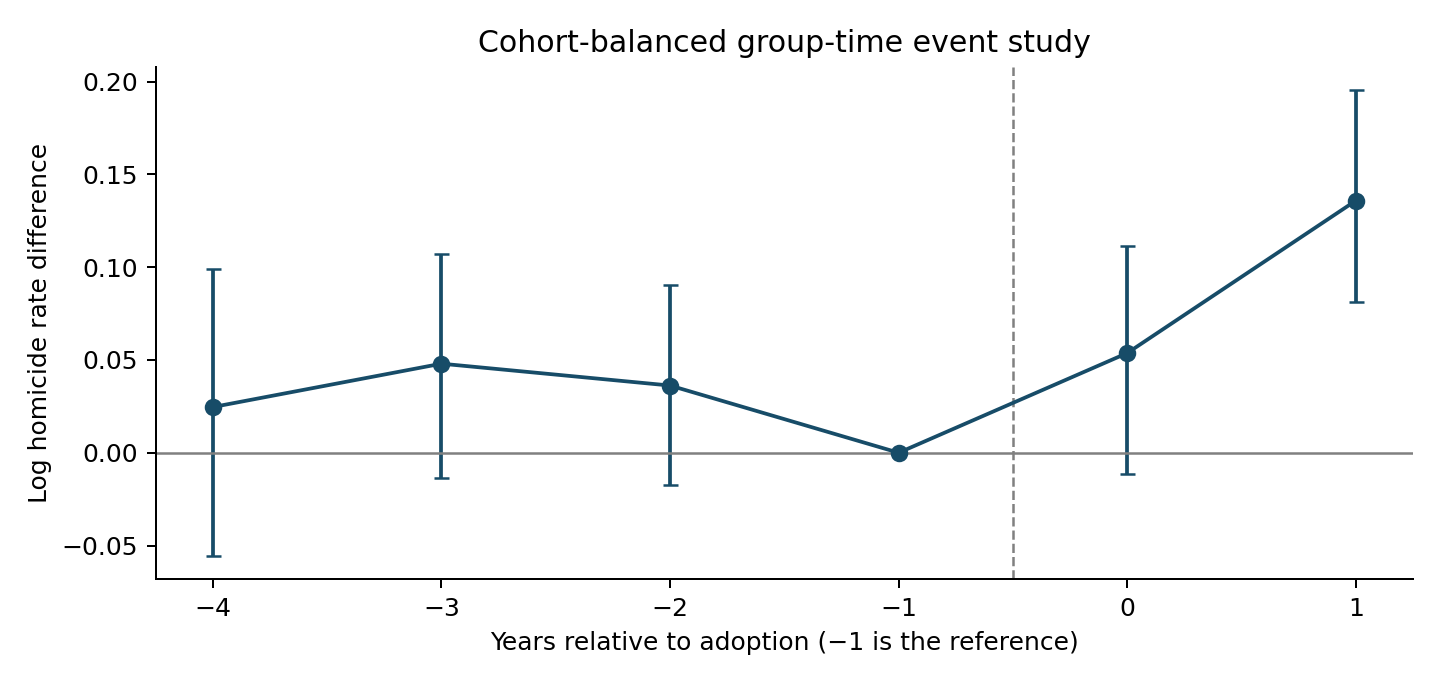

In [9]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'output/event_study.png')))

## 3. Prespecified specification curve

In [10]:
print(pd.read_csv(ROOT / 'output/specification_curve.csv').to_string(index=False))

    sample  weighted  region_year  controls     beta       se        lo       hi        p  exact_pct   n  clusters  rank  k_absorbed  default_cluster_se  correction
All states      True        False     False 0.080064 0.034225  0.011286 0.148841 0.023438   8.335587 550        50    61          12            0.035898    1.041272
All states      True        False      True 0.086926 0.032128  0.022362 0.151489 0.009354   9.081544 550        50    73          24            0.033738    1.065027
All states      True         True     False 0.094588 0.027865  0.038591 0.150585 0.001370   9.920561 550        50    91          42            0.029315    1.102764
All states      True         True      True 0.093675 0.028986  0.035426 0.151925 0.002202   9.820297 550        50   103          54            0.030533    1.129444
All states     False        False     False 0.087701 0.063780 -0.040469 0.215872 0.175367   9.166209 550        50    61          12            0.066899    1.041272
All states

**My interpretation.** All points are retained. Changing weights and samples changes the target population; significance across correlated models is not a probability that the claim is true.

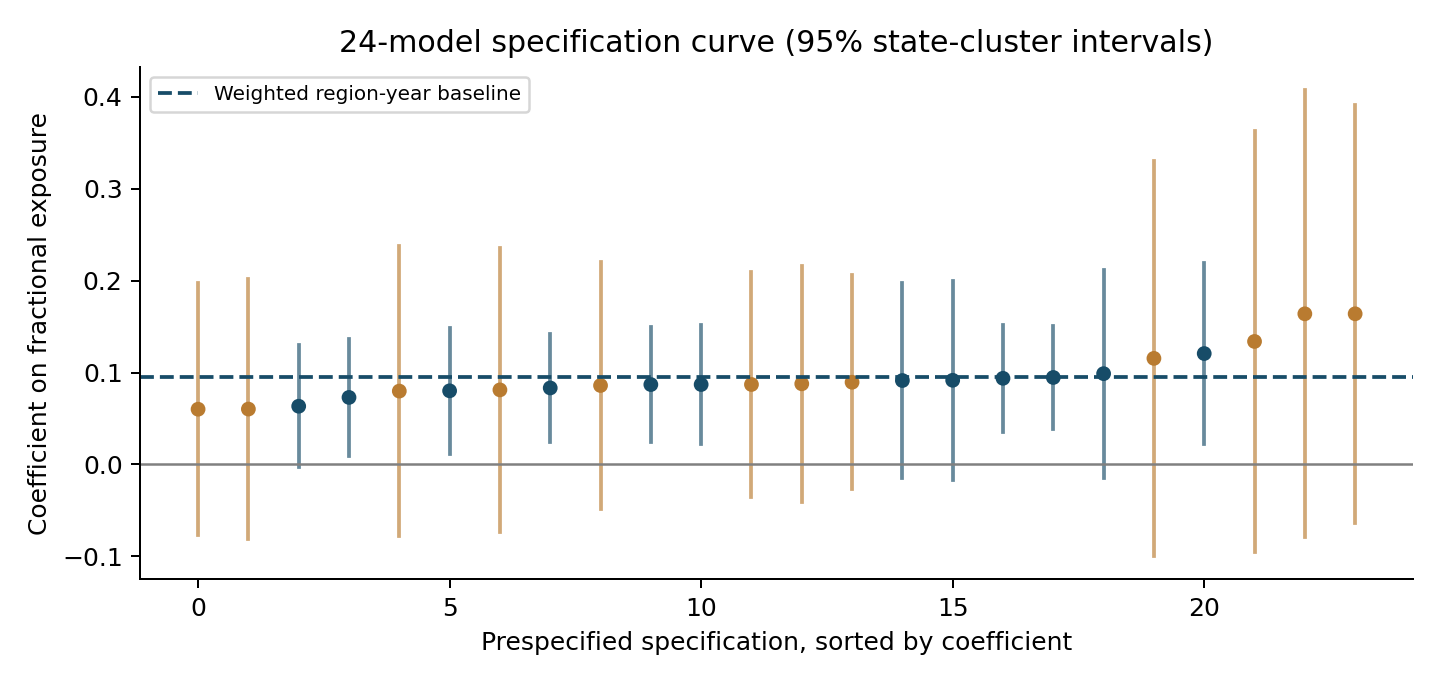

In [11]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'output/specification_curve.png')))

## 4. Leave-one-state-out influence

In [12]:
print(pd.read_csv(ROOT / 'output/leave_one_state_out.csv').to_string(index=False))

 omitted_state        change     beta       se       lo       hi        p  exact_pct   n  clusters  rank  k_absorbed  default_cluster_se  correction
       Florida -1.138747e-02 0.083200 0.029386 0.024115 0.142286 0.006755   8.675944 539        49    90          42            0.030917    1.105047
     Minnesota -1.130177e-02 0.083286 0.027326 0.028344 0.138228 0.003741   8.685258 539        49    90          42            0.028749    1.105047
      Missouri -1.042796e-02 0.084160 0.025804 0.032278 0.136042 0.002043   8.780270 539        49    90          42            0.027148    1.105047
  South Dakota -8.934736e-03 0.085653 0.025563 0.034255 0.137051 0.001578   8.942824 539        49    90          42            0.026895    1.105047
      Illinois -7.157846e-03 0.087430 0.030251 0.026607 0.148253 0.005765   9.136575 539        49    90          42            0.031827    1.105047
    California -3.919224e-03 0.090669 0.028575 0.033215 0.148122 0.002632   9.490600 539        49    90  

**My interpretation.** The positive pooled result does not depend on Florida alone. The state-deletion difference is not an identified state-specific causal effect.

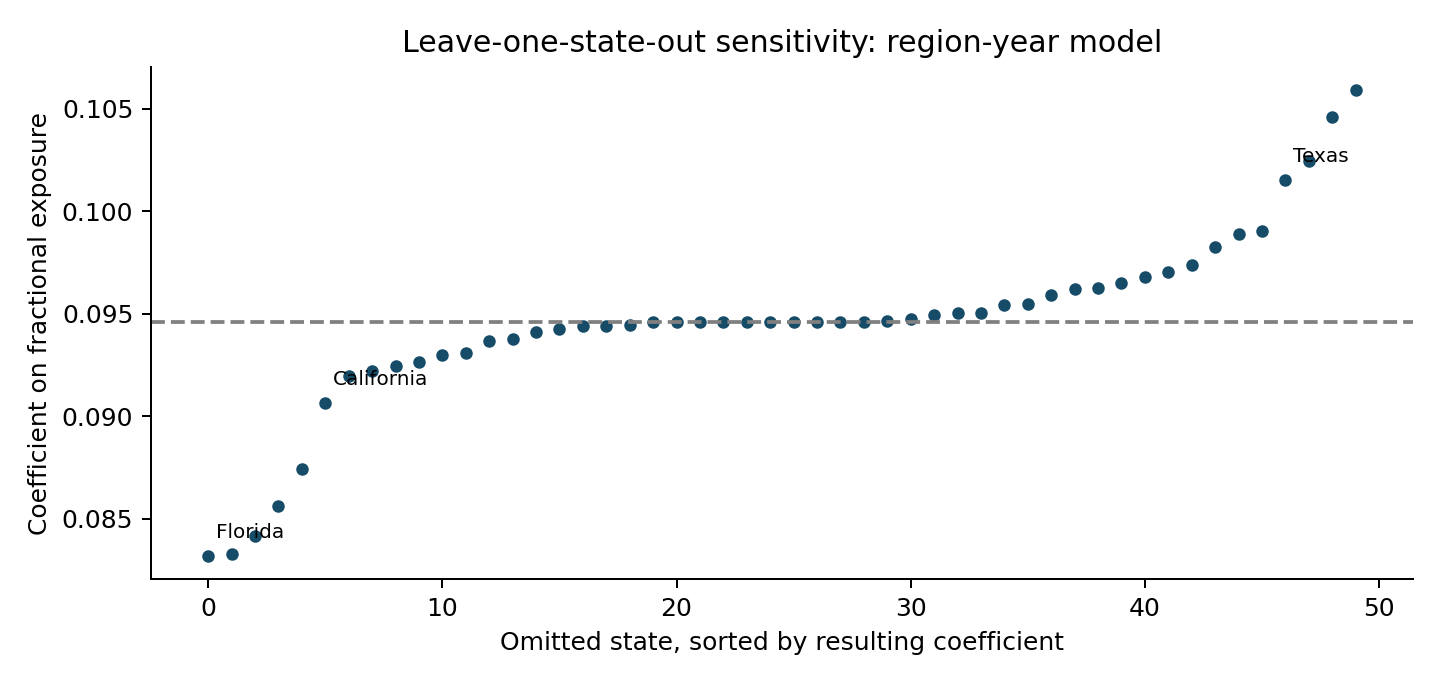

In [13]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'output/state_influence.png')))

## 5. Restricted wild cluster inference

In [14]:
print(pd.read_csv(ROOT / 'output/inference.csv').to_string(index=False))

    beta  cluster_se  cluster_t_p  wild_p  wild_mc_se  draws  exceedances     seed
0.094588    0.027865      0.00137  0.0035    0.001321   1999            6 20261120


**My interpretation.** The positive region-year coefficient survives a different finite-sample reference distribution. Resampling does not repair a violation of parallel trends.

## Additional outcome diagnostics

In [15]:
print(pd.read_csv(ROOT / 'output/placebo_outcomes.csv').to_string(index=False))

  outcome  region_year      beta       se        lo       hi        p  exact_pct   n  clusters  rank  k_absorbed  default_cluster_se  correction
l_larceny        False  0.003000 0.016144 -0.029443 0.035443 0.853335   0.300481 550        50    61          12            0.016934    1.041272
l_larceny         True -0.006604 0.014660 -0.036065 0.022857 0.654356  -0.658225 550        50    91          42            0.015423    1.102764
  l_motor        False  0.051653 0.056252 -0.061390 0.164697 0.362992   5.301045 550        50    61          12            0.059004    1.041272
  l_motor         True -0.038856 0.044846 -0.128978 0.051266 0.390481  -3.811064 550        50    91          42            0.047179    1.102764


**My interpretation.** These original-style falsification checks are not counted as a novel extension. A non-rejection is not proof that the design is valid.

## My overall judgment

The positive pooled relationship survives these exercises, while its exact magnitude remains conditional on comparisons, weights and the reference year. I have not established a common effect in every state or identified whether additional deaths were legally justified. The report and references explain those limits.

## Peer audit

I am assigned to audit Roman Carrubba’s Card (1995) replication, and Julia Clark is assigned to audit my Cheng–Hoekstra repository. Roman’s repository URL is still needed. The project deadline is Thursday 19 November at 11:59 pm; the audit issue is due Sunday 22 November at 11:59 pm. I will run the final version from a clean checkout, file an approximately 300-word issue and add its URL as a Canvas submission comment. No peer run or filed issue has been completed yet.